In [44]:
import matplotlib.pyplot as plt
import pandas as pd


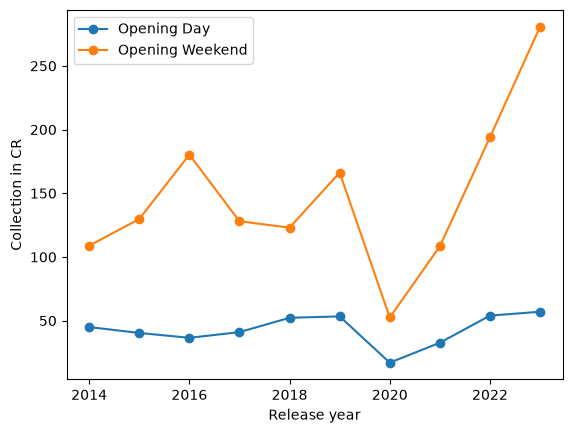

In [ ]:
df=pd.read_csv("movie_data.csv")
df.columns
df["Release Date"]=pd.to_datetime(df["Release Date"]).dt.year

df1=df[["Movie Name","Release Date","Opening Day","Opening Weekend"]]

# replace values
df1["Opening Day"]=(df1["Opening Day"].replace("0 Cr N.A",pd.NA))
df1["Opening Weekend"]=(df1["Opening Weekend"].replace("0 Cr N.A",pd.NA))

# remove cr

df1["Opening Day"]=(df1["Opening Day"].str.replace("Cr","",regex=False).pipe(pd.to_numeric,errors="coerce"))
df1["Opening Weekend"]=(df1["Opening Weekend"].str.replace("Cr","",regex=False).pipe(pd.to_numeric,errors="coerce"))


df1 = df1[(df1["Release Date"] >= 2014) ]
df1 = df1.dropna()
df1=df1.loc[df1.groupby("Release Date")["Opening Day"].idxmax()]
df1=df1.reset_index(drop=True)
x=df1["Release Date"]
y=df1["Opening Day"]
y1=df1["Opening Weekend"]
plt.plot(x,y,label="Opening Day",marker="o")
plt.plot(x,y1,label="Opening Weekend",marker="o")
plt.ylabel("Collection in CR")
plt.xlabel("Release year")
plt.title("Bollywood COLLECTION")
plt.legend()
# plt.savefig("Bollywood_analisis.png")
